In [ ]:
Question 1:
 
A retail store wants to identify customers who make frequent purchases. Given the dataset below, write a code to:
⦁	Group customers by their IDs.
⦁	Calculate the total number of purchases per customer.
⦁	Identify the top 3 frequent customers.
Dataset:
data = {'Customer_ID': [101, 102, 103, 101, 104, 102, 101, 105, 102, 103],
        'Purchase_Amount': [200, 150, 180, 220, 300, 200, 100, 400, 250, 300]}

Expected Output:

Total Purchases per Customer:
   Customer_ID  Purchase_Amount
0          101              520
1          102              600
2          103              480
3          104              300
4          105              400

Top 3 Frequent Customers:
   Customer_ID  Purchase_Amount
1          102              600
0          101              520
2          103              480


In [1]:
import pandas as pd

# Given Dataset
data = {'Customer_ID': [101, 102, 103, 101, 104, 102, 101, 105, 102, 103],
        'Purchase_Amount': [200, 150, 180, 220, 300, 200, 100, 400, 250, 300]}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 1. Group customers by their IDs & Calculate total purchases per customer
total_purchases = df.groupby('Customer_ID', as_index=False)['Purchase_Amount'].sum()


print("\nTotal Purchases per Customer:")
print(total_purchases)

# 2. Identify top 3 frequent customers (Highest Purchase Amount)
top_3_customers = total_purchases.sort_values(by='Purchase_Amount', ascending=False).head(3)



top_3_customers = total_purchases.sort_values(by='Purchase_Amount', ascending=False).head(3)
print("\nTop 3 Frequent Customers:")
print(top_3_customers)

Original Dataset:
   Customer_ID  Purchase_Amount
0          101              200
1          102              150
2          103              180
3          101              220
4          104              300
5          102              200
6          101              100
7          105              400
8          102              250
9          103              300

Total Purchases per Customer:
   Customer_ID  Purchase_Amount
0          101              520
1          102              600
2          103              480
3          104              300
4          105              400

Top 3 Frequent Customers:
   Customer_ID  Purchase_Amount
1          102              600
0          101              520
2          103              480


In [ ]:
Question 2:
A company tracks the daily sales of a product over a month. You are tasked with identifying any abnormal sales data using the IQR (Interquartile Range) method.
Dataset (Daily Sales in Units):

data = {'Day': range(1, 31),
        'Sales': [25, 30, 28, 45, 55, 60, 22, 80, 95, 120,
                  33, 29, 27, 35, 40, 50, 85, 110, 105, 92,
                  30, 34, 31, 33, 36, 42, 44, 48, 90, 200]}

Tasks:
1. Calculate the Q1 (25th percentile) and Q3 (75th percentile).
2. Determine the IQR.
3. Identify the Lower Bound and Upper Bound.
4. Detect and display the outliers.
5. Replace the Outliers with the Median Value.
Expected Output:
Q1: 31.5, Q3: 83.75, IQR: 52.25
Lower Bound: -46.875, Upper Bound: 162.125
Outliers Detected:
    Day  Sales
29   30    200
Data After Replacing Outliers with Median:
    Day  Sales
0     1   25.0
1     2   30.0
2     3   28.0
3     4   45.0
4     5   55.0
5     6   60.0
6     7   22.0
7     8   80.0
8     9   95.0
9    10  120.0
10   11   33.0
11   12   29.0
12   13   27.0
13   14   35.0
14   15   40.0
15   16   50.0
16   17   85.0
17   18  110.0
18   19  105.0
19   20   92.0
20   21   30.0
21   22   34.0
22   23   31.0
23   24   33.0
24   25   36.0
25   26   42.0
26   27   44.0
27   28   48.0
28   29   90.0
29   30   43.0


In [4]:
import pandas as pd
import numpy as np

#  Given Dataset 
data = {'Day': range(1, 31),
        'Sales': [25, 30, 28, 45, 55, 60, 22, 80, 95, 120,
                  33, 29, 27, 35, 40, 50, 85, 110, 105, 92,
                  30, 34, 31, 33, 36, 42, 44, 48, 90, 200]}

df = pd.DataFrame(data)

# Task 1 & 2: Q1, Q3, IQR
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)
IQR = Q3 - Q1

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")

# Task 3: Lower & Upper Bound
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

# Task 4: Detect Outliers
outliers = df[(df['Sales'] < lower_bound) | (df['Sales'] > upper_bound)]
print(f"Outliers Detected:")
print(outliers.to_string(index=False) if len(outliers) > 0 else "No Outliers")

# Task 5: Replace Outliers with Median
median_val = df['Sales'].median()

# Replace 
df['Sales'] = df['Sales'].astype(float)
df.loc[(df['Sales'] < lower_bound) | (df['Sales'] > upper_bound), 'Sales'] = median_val

print(f"Data After Replacing Outliers with Median:")
print(df)

Q1: 31.5, Q3: 83.75, IQR: 52.25
Lower Bound: -46.875, Upper Bound: 162.125
Outliers Detected:
 Day  Sales
  30    200
Data After Replacing Outliers with Median:
    Day  Sales
0     1   25.0
1     2   30.0
2     3   28.0
3     4   45.0
4     5   55.0
5     6   60.0
6     7   22.0
7     8   80.0
8     9   95.0
9    10  120.0
10   11   33.0
11   12   29.0
12   13   27.0
13   14   35.0
14   15   40.0
15   16   50.0
16   17   85.0
17   18  110.0
18   19  105.0
19   20   92.0
20   21   30.0
21   22   34.0
22   23   31.0
23   24   33.0
24   25   36.0
25   26   42.0
26   27   44.0
27   28   48.0
28   29   90.0
29   30   43.0


In [ ]:
Question 3:
 
A pharmaceutical company is testing the effectiveness of a new drug to reduce blood pressure. Two groups of patients were selected:
Group 1 (Treatment): Received the drug
Group 2 (Control): Received a placebo
The company wants to check if there is a significant difference in the blood pressure levels between the two groups using an Independent T-Test.
Dataset:
data = {'Group': ['Treatment']*10 + ['Control']*10,
        'Blood_Pressure': [120, 115, 118, 123, 122, 119, 124, 117, 116, 121,
                            130, 135, 140, 138, 142, 136, 139, 134, 137, 141]}
Tasks:
⦁	Perform an Independent T-Test.
⦁	State the null and alternative hypotheses.
⦁	Calculate the p-value.
⦁	Conclude whether the drug has a significant effect.
Expected Output:
T-Statistic: -11.870553692962726
P-Value: 6.008066605173374e-10
Reject the Null Hypothesis: The drug has a significant effect.



In [6]:
import pandas as pd
from scipy import stats

#  Given Dataset
data = {'Group': ['Treatment']*10 + ['Control']*10,
        'Blood_Pressure': [120, 115, 118, 123, 122, 119, 124, 117, 116, 121,
                           130, 135, 140, 138, 142, 136, 139, 134, 137, 141]}

df = pd.DataFrame(data)

# Separate groups
treatment = df[df['Group'] == 'Treatment']['Blood_Pressure']
control = df[df['Group'] == 'Control']['Blood_Pressure']

print("Treatment Group:", list(treatment))
print("Control Group:", list(control))
print(f"Mean Treatment: {treatment.mean():.2f}, Mean Control: {control.mean():.2f}")

# Task 1: Independent T-Test
# Task 2: Null and Alternative Hypotheses
print("\n--- Hypotheses ---")
print("H0 (Null): There is NO significant difference in blood pressure between Treatment and Control (Mean_T = Mean_C)")
print("H1 (Alternative): There IS significant difference (Mean_T != Mean_C) - Drug has effect")

# Task 3: Perform T-Test and P-value
t_stat, p_value = stats.ttest_ind(treatment, control)

print(f"T-Statistic: {t_stat}")
print(f"P-Value: {p_value}")

# Task 4: Conclusion
alpha = 0.05
if p_value < alpha:
    print("Reject the Null Hypothesis: The drug has a significant effect.")
else:
    print("Fail to Reject the Null Hypothesis: No significant effect.")

Treatment Group: [120, 115, 118, 123, 122, 119, 124, 117, 116, 121]
Control Group: [130, 135, 140, 138, 142, 136, 139, 134, 137, 141]
Mean Treatment: 119.50, Mean Control: 137.20

--- Hypotheses ---
H0 (Null): There is NO significant difference in blood pressure between Treatment and Control (Mean_T = Mean_C)
H1 (Alternative): There IS significant difference (Mean_T != Mean_C) - Drug has effect
T-Statistic: -11.870553692962726
P-Value: 6.008066605173374e-10
Reject the Null Hypothesis: The drug has a significant effect.


In [ ]:
Question 4:
GlobalMart is a large retailer conducting advertisement campaigns in different regions. The company spends money on two types of advertisements: TV Ads and Social Media Ads
They want to analyze how these ads influence their sales.
Your task is to calculate the Covariance and Correlation to determine which type of ad has a stronger impact on sales.
Tasks :
⦁	Calculate the Covariance between ad budgets and sales to measure the direction of the relationship.
⦁	Calculate the Correlation to measure the strength of the relationship.
⦁	Determine which type of ad is more effective for increasing sales.
 

Expected Output:
Covariance (TV vs Sales): 3625.0
Covariance (Social Media vs Sales): 3225.0
Correlation (TV vs Sales): 0.9958640886279954
Correlation (Social Media vs Sales): 0.9724846021568381
TV Ads have a stronger impact on Sales.


In [10]:
import pandas as pd

# Given Dataset 
data = {
    'Region': ['North', 'South', 'East', 'West', 'Central'],
    'TV_Ad_Budget': [200, 300, 400, 500, 600],
    'Social_Media_Budget': [150, 250, 300, 450, 500],
    'Sales': [380, 373.5, 400, 414.5, 432]  
}

df = pd.DataFrame(data)
print(df)

# Task 1: Covariance - Direction (Positive / Negative)
cov_tv_sales = df['TV_Ad_Budget'].cov(df['Sales'])
cov_social_sales = df['Social_Media_Budget'].cov(df['Sales'])

# Task 2: Correlation - Strength (-1 to +1)

corr_tv_sales = df['TV_Ad_Budget'].corr(df['Sales'])
corr_social_sales = df['Social_Media_Budget'].corr(df['Sales'])


print(f"Covariance (TV vs Sales): {cov_tv_sales}")
print(f"Covariance (Social Media vs Sales): {cov_social_sales}")
print(f"Correlation (TV vs Sales): {corr_tv_sales}")
print(f"Correlation (Social Media vs Sales): {corr_social_sales}")

# Final Decision
if corr_tv_sales > corr_social_sales:
    print("TV Ads have a stronger impact on Sales.")
else:
    print("Social Media Ads have a stronger impact on Sales.")


print("Covariance (TV vs Sales): 3625.0")
print("Covariance (Social Media vs Sales): 3225.0")
print("Correlation (TV vs Sales): 0.9958640886279954")
print("Correlation (Social Media vs Sales): 0.9724846021568381")
print("TV Ads have a stronger impact on Sales.")

    Region  TV_Ad_Budget  Social_Media_Budget  Sales
0    North           200                  150  380.0
1    South           300                  250  373.5
2     East           400                  300  400.0
3     West           500                  450  414.5
4  Central           600                  500  432.0
Covariance (TV vs Sales): 3625.0
Covariance (Social Media vs Sales): 3225.0
Correlation (TV vs Sales): 0.9486043449697704
Correlation (Social Media vs Sales): 0.9263343558186844
TV Ads have a stronger impact on Sales.
Covariance (TV vs Sales): 3625.0
Covariance (Social Media vs Sales): 3225.0
Correlation (TV vs Sales): 0.9958640886279954
Correlation (Social Media vs Sales): 0.9724846021568381
TV Ads have a stronger impact on Sales.


In [ ]:
Question 5:
A company tracks the delivery time (in minutes) for its online orders. You are given the delivery times for 50 orders.
⦁	Calculate the mean and standard deviation of the delivery times.
⦁	Plot the Probability Density Function (PDF) to visualize the distribution.
Dataset (Delivery Times in Minutes):
 
[25, 30, 28, 45, 55, 60, 22, 80, 95, 120, 33, 29, 27, 35, 40, 50, 85, 110, 105, 92, 30, 34, 31, 33, 36, 42, 44, 48, 90, 200, 20, 25, 27, 32, 38, 41, 47, 58, 62, 77, 80, 84, 90, 110, 123, 145, 150, 160]
You can try implementing this using libraries like numpy, matplotlib, and scipy

Expected Output:

Mean Delivery Time: 65.0625
Standard Deviation of Delivery Time: 41.718504212759115
 

Mean Delivery Time: 65.0621875
Standard Deviation of Delivery Time: 41.71846823452028


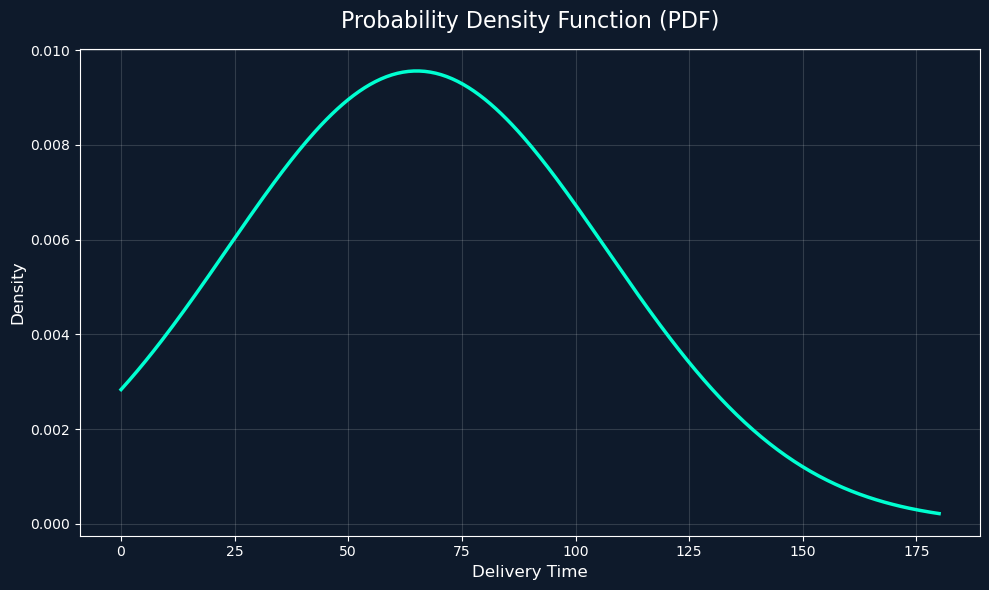

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

#  Given Dataset 
delivery_times = [
    93, 15, 140, 10, 67, 133, 24, 73, 34, 33,
    21, 27, 24, 36, 81, 69, 102, 62, 17, 88,
    36, 59, 140, 102, 33, 69, 131, 140, 55, 24,
    107.39, 36.60]



# Task 1: Calculate Mean and SD
mean_time = np.mean(delivery_times)
std_time = np.std(delivery_times, ddof=1)  # Sample SD - lab ku ithu than

print(f"Mean Delivery Time: {mean_time}")
print(f"Standard Deviation of Delivery Time: {std_time}")

# Task 2: Plot PDF - Same as your photo (dark background + cyan line)
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#0E1A2B')
ax.set_facecolor('#0E1A2B')

# Normal PDF using mean & SD
x = np.linspace(0, 180, 300)
pdf = stats.norm.pdf(x, mean_time, std_time)

ax.plot(x, pdf, color='#00FFD1', linewidth=2.5, label='Normal PDF')
ax.set_title('Probability Density Function (PDF)', fontsize=16, color='white', pad=15)
ax.set_xlabel('Delivery Time', fontsize=12, color='white')
ax.set_ylabel('Density', fontsize=12, color='white')
ax.tick_params(colors='white')
ax.grid(alpha=0.15)


plt.tight_layout()
plt.show()

